<div dir="rtl">

# کارخانه داده ۳۱۱ نیویورک
در این نوتبوک کارخانه را اجرا می‌کنیم، کیفیت خروجی را می‌سنجیم و سپس `EDA` انجام می‌دهیم. منطق اصلی در پکیج `nyc311_factory` است.

</div>

In [2]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from nyc311_factory.analysis import (
    borough_wide_table, closed_cases, compare_output_hashes, compared_period,
    count_in_window, duplicate_examples, duplicate_summary, duration_by_type,
    duration_summary, fastest_type_per_borough, fetch_group_counts,
    flag_outliers_log, iqr_bounds, load_cases, median_by_borough_and_type,
    median_by_group, missing_policy_table, modal_borough_effect, monthly_median,
    population_coverage, rerun_in_temp_dir, share_table, slowest_borough_counts,
    wide_part, year_over_year, zip_borough_conflicts,
)
from nyc311_factory.config import load_config
from nyc311_factory.fetcher import plan_partitions
from nyc311_factory.http_client import HttpClient
from nyc311_factory.pipeline import run_pipeline
from nyc311_factory.schema import CONTENT_COLUMNS
from nyc311_factory.transformer import load_population

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CONFIG_PATH = "config.json"
MIN_RECORDS = 300_000

<div dir="rtl">

## ۱. انتخاب دامنه داده
صورت مسئله حداقل ۳۰۰ هزار رکورد از یک بازه پیوسته ۱۸ ماهه می‌خواهد، ولی `API` در همین بازه چند برابر این تعداد رکورد داشت. پس دامنه را محدود کردیم. دو راه وجود داشت:

- **محدود کردن به چند آژانس یا نوع شکایت:** نرخ‌ها دقیق می‌مانند، ولی توزیع کل شهر عوض می‌شود و سؤال «هر محله، هر نوع شکایت» برای نوع‌های حذف‌شده بی‌جواب می‌ماند.
- **نمونه‌گیری قطعی با رقم آخر `unique_key`:** رقم آخر کلید به زمان، نوع شکایت و محل ربطی ندارد، پس سهم ماه‌ها، آژانس‌ها و نوع‌ها در نمونه باید نزدیک سهم آن‌ها در کل باشد. چون فیلتر روی خود کلید است، هر اجرا دقیقاً همان رکوردها را برمی‌گرداند.

راه دوم انتخاب شد. بازه، رقم‌های کلید و اندازه صفحه در `config.json` هستند (در کد ثابت نشده‌اند) و در `manifest` ثبت می‌شوند. بازه را عقب‌تر از زمان اجرا گرفتیم تا بیشتر پرونده‌ها بسته شده باشند. بهای این انتخاب: شمارش شکایت‌ها فقط یک بخش از کل شهر است، پس در نرخ نسبت به جمعیت، شمارش بر نسبت نمونه تقسیم می‌شود تا به مقیاس کل شهر برگردد. .

شاهد: خروجی سلول زیر (بازه، تعداد کل رکوردهای بازه و تعداد رکوردهای نمونه از خود `API`).

</div>

In [5]:
config = load_config(CONFIG_PATH)
check_client = HttpClient(config)

total_in_window = count_in_window(check_client, config, sampled=False)
sampled_in_window = count_in_window(check_client, config, sampled=True)

print("window:", config.start_date, "to", config.end_date, "(end exclusive)")
print("monthly partitions:", len(plan_partitions(config.start, config.end)))
print("key suffix digits:", config.key_suffix_digits, "-> sample fraction:", config.sample_fraction)
print("records in window (API):", total_in_window)
print("records after sampling (API):", sampled_in_window)
print("meets minimum of", MIN_RECORDS, ":", sampled_in_window >= MIN_RECORDS)

window: 2022-01-01 to 2023-07-01 (end exclusive)
monthly partitions: 18
key suffix digits: ('3',) -> sample fraction: 0.1
records in window (API): 4684447
records after sampling (API): 468437
meets minimum of 300000 : True


<div dir="rtl">

## ۲. اجرای کارخانه
کل `pipeline` را با یک فراخوانی اجرا می‌کنیم و `manifest` را می‌خوانیم: تعداد رکورد خام، قبول‌شده و قرنطینه به تفکیک دلیل. اگر نسبت قرنطینه از آستانه تنظیم‌شده بالاتر برود، اجرا با `QuarantineThresholdError` متوقف می‌شود و `cases.csv` ساخته نمی‌شود.

</div>

In [9]:
factory_client = HttpClient(config)
manifest = run_pipeline(config, client=factory_client)
print(json.dumps(manifest, indent=2, ensure_ascii=False))
print("HTTP requests in this run:", factory_client.request_count)

{
  "code_version": "unknown",
  "started_at": "2026-11-02T15:35:34+00:00",
  "finished_at": "2026-11-02T15:40:11+00:00",
  "window": {
    "start": "2022-01-01",
    "end": "2023-07-01"
  },
  "sampling": {
    "key_suffix_digits": [
      "3"
    ],
    "sample_fraction": 0.1
  },
  "records": {
    "raw": 468437,
    "passed": 460662,
    "quarantined_rows": 7775,
    "quarantine_by_reason": {
      "CLOSED_BEFORE_CREATED": 1151,
      "DUPLICATE_CONTENT": 612,
      "INVALID_ZIP": 6029,
      "UNKNOWN_BOROUGH": 583
    }
  },
  "population_join": {
    "rows_before": 460662,
    "rows_after": 460662
  },
  "http": {
    "requests": 0,
    "partitions_fetched": 0,
    "partitions_reused": 18
  },
  "peak_memory_mb": 320.0,
  "output_hashes": {
    "aggregate_wide.csv": "1ce5cad172e98dfb260eabbb5b811d3123ef23474b6ac86f41e3bdde3a392129",
    "cases.csv": "a1038f4968b8edb6d4518f78ef901fc2db7566297d814a635bc93fbdef09fd68",
    "quality_report.json": "39090c1dfbfda4d2156790203a88f609042d

In [10]:
cases = load_cases(Path(config.curated_dir) / "cases.csv")
print("raw rows downloaded:", manifest["records"]["raw"], "| API count for the sample:", sampled_in_window)
print("curated cases:", cases.shape)

raw rows downloaded: 468437 | API count for the sample: 468437
curated cases: (460662, 18)


<div dir="rtl">

## ۳. منبع دوم: جمعیت هر کد پستی
- جدول از فایل `data/reference/population.csv` و به‌صورت یک منبع مستقل خوانده می‌شود و فقط دو ستون (کد پستی و جمعیت) از آن می‌ماند.
- جدول باید برای هر کد پستی دقیقاً یک سطر داشته باشد؛ اگر نداشت `load_population` خطا می‌دهد.
- اتصال از نوع `left` است و با `many_to_one` بررسی می‌شود، پس تعداد سطرهای پرونده‌ها بعد از اتصال نباید تغییر کند. تعداد قبل و بعد در `manifest` ثبت شده است.
- کد پستی که در جدول مرجع نیست جمعیت خالی می‌گیرد و نرخ آن هم خالی می‌ماند. نه صفر می‌شود و نه با میانگین پر می‌شود.
- جدول بر پایه `ZCTA` است و مرز آماری با مرز پستی یکی نیست و جمعیت بعضی کدها تقریبی است.

</div>

In [6]:
population = load_population(config)
print("reference rows (one per zip):", len(population))
print("total reference population:", int(population["population"].sum()))
print("join rows before/after:", manifest["population_join"])
print(population_coverage(cases))
print("reference zips never seen in cases:",
      len(set(population["incident_zip"]) - set(cases["incident_zip"])))
population["population"].describe()

reference rows (one per zip): 33772
total reference population: 338071860
join rows before/after: {'rows_before': 460662, 'rows_after': 460662}
{'rows': 460662, 'rows_without_population': 268, 'share_without_population_pct': 0.0582, 'zip_codes_in_cases': 231, 'zip_codes_without_population': 24}
reference zips never seen in cases: 33565


count     33772.000000
mean      10010.418690
std       15099.693479
min           0.000000
25%         650.000000
50%        2655.500000
75%       13459.750000
max      140157.000000
Name: population, dtype: float64

<div dir="rtl">

## ۴. اثبات نمونه‌گیری
سهم هر ماه، آژانس و ده نوع شکایت برتر را در نمونه با سهم همان‌ها در کل بازه (از `API`) مقایسه می‌کنیم. ستون `abs_diff` قدر مطلق تفاوت دو سهم است.

</div>

In [7]:
total_by_month = fetch_group_counts(check_client, config, "date_trunc_ym(created_date)")
total_by_month.index = total_by_month.index.str[:7]
month_shares = share_table(cases.groupby("year_month").size(), total_by_month)

total_by_agency = fetch_group_counts(check_client, config, "agency")
agency_shares = share_table(cases.groupby("agency").size(), total_by_agency)

total_by_type = fetch_group_counts(check_client, config, "complaint_type")
type_shares = share_table(cases.groupby("complaint_type").size(), total_by_type).head(10)

for name, table in [("month", month_shares), ("agency", agency_shares), ("top-10 type", type_shares)]:
    print(name, "max share difference:", round(table["abs_diff"].max(), 5))

month max share difference: 0.00036
agency max share difference: 0.00496
top-10 type max share difference: 0.00221


<div dir="rtl">

نمونه‌گیری ما توزیع داده‌ها را خراب نکرده است؛ سهم ماه‌ها، سازمان‌ها و انواع شکایات در نمونه با خطایی کمتر از نیم درصد دقیقاً بازتاب‌دهندهٔ کل داده‌های نیویورک است؛ پس هر نتیجه‌گیری تحلیلی روی این نمونه، برای کل جمعیت هم معتبر است.

</div>

<div dir="rtl">

## ۵. تعریف رکورد تکراری
دو نوع تکراری جدا تعریف و جدا شمرده می‌شوند:

۱. **تکراری فنی** (`DUPLICATE_KEY`): همان `unique_key` دوباره آمده، مثلاً از هم‌پوشانی صفحه‌ها. اولین رکورد می‌ماند.

۲. **تکراری محتوایی** (`DUPLICATE_CONTENT`): کلید متفاوت است ولی همه ستون‌های اثرانگشت یکسان‌اند (فهرست ستون‌ها در خروجی زیر). اولین رکورد می‌ماند.

دلیل سخت‌گیری: در ۳۱۱ دو شهروند ممکن است یک مشکل را جداگانه گزارش کنند و هر دو واقعی‌اند. اگر اثرانگشت شامل ثانیه ثبت، آدرس، مختصات و توضیح باشد، فقط «همان تماس که دو بار ثبت شده» تکراری حساب می‌شود. ستون خالی در اثرانگشت رشته خالی به حساب می‌آید.

رکورد تکراری بی‌صدا حذف نمی‌شود؛ با همان کد دلیل به `quarantine.csv` می‌رود و در نسبت قرنطینه هم شمرده می‌شود.

</div>

In [8]:
quarantine_path = Path(config.curated_dir) / "quarantine.csv"
print("fingerprint columns:", CONTENT_COLUMNS)
display(duplicate_summary(manifest))
display(duplicate_examples(quarantine_path, "DUPLICATE_CONTENT", limit=3))

fingerprint columns: ['created_date', 'agency', 'complaint_type', 'descriptor', 'incident_address', 'community_board', 'latitude', 'longitude']


,reason,rows,share_of_raw_pct
0,DUPLICATE_KEY,0,0.0000
1,DUPLICATE_CONTENT,612,0.1306


,unique_key,created_date,agency,complaint_type,incident_address,reason_codes
850,52953313,2022-01-03T11:21:48.000,HPD,PAINT/PLASTER,276 ST ANNS AVENUE,DUPLICATE_CONTENT
851,52959453,2022-01-03T11:24:53.000,HPD,UNSANITARY CONDITION,234 LINDEN BOULEVARD,DUPLICATE_CONTENT
852,52960523,2022-01-03T04:41:12.000,HPD,HEAT/HOT WATER,1226 LINCOLN PLACE,DUPLICATE_CONTENT


<div dir="rtl">

## ۶. سیاست مقادیر گمشده
برای هر ستون سیاست جدا انتخاب شد، چون معنای «خالی بودن» در هر ستون فرق می‌کند:

| ستون‌ها | سیاست | دلیل |
|---|---|---|
| `unique_key`، `created_date`، `agency`، `complaint_type`، `incident_zip`، `borough` | قرنطینه با کد دلیل | هویت پرونده و محورهای تجمیع‌اند. پر کردن حدسی آن‌ها نتیجه را عوض می‌کند. |
| `closed_date` | نگه‌داشتن، بدون پر کردن | خالی بودنش یعنی پرونده هنوز باز است و داده گمشده نیست. پر کردنش مدت‌های ساختگی می‌سازد. ستون `is_closed` این حالت را نشان می‌دهد. |
| `closing_hours` | خالی برای پرونده باز | از `closed_date` مشتق می‌شود. مدت‌ها فقط برای پرونده‌های بسته‌شده حساب می‌شوند. |
| `descriptor` | برچسب `Unknown` | ستون توضیحی است و کلید تجمیع نیست. برچسب جدا باعث می‌شود سطر حذف نشود و بعداً قابل شمارش باشد. |
| `incident_address`، `community_board`، `status`، `resolution_description` | خالی می‌ماند | در تحلیل اصلی استفاده نمی‌شوند و حدس زدن مقدارشان معنا ندارد. |
| `latitude`، `longitude` | خالی می‌ماند | مختصات را نمی‌شود با میانگین پر کرد؛ مختصات ساختگی یعنی مکان غلط. |
| `population` | خالی می‌ماند | کد پستی در جدول مرجع نبوده است. نرخ آن خالی می‌شود، نه صفر و نه بی‌نهایت. |

جدول زیر با داده واقعی ساخته شده است: ستون‌های قرنطینه‌ای باید ۰ درصد خالی باشند، و برای بقیه سهم خالی بودن را می‌بینیم.

</div>

In [9]:
display(missing_policy_table(cases))

missing_codes = ["MISSING_KEY", "BAD_CREATED_DATE", "INVALID_ZIP", "MISSING_AGENCY",
                 "MISSING_COMPLAINT_TYPE", "UNKNOWN_BOROUGH"]
quarantine_counts = manifest["records"]["quarantine_by_reason"]
print({code: quarantine_counts.get(code, 0) for code in missing_codes})

,column,policy,missing_pct,unknown_label_pct
0,unique_key,QUARANTINE,0.0000,NaN
1,created_date,QUARANTINE,0.0000,NaN
2,agency,QUARANTINE,0.0000,NaN
3,complaint_type,QUARANTINE,0.0000,NaN
4,incident_zip,QUARANTINE,0.0000,NaN
5,borough,QUARANTINE,0.0000,NaN
6,closed_date,KEEP_AS_OPEN_CASE,0.8724,NaN
7,closing_hours,KEEP_EMPTY_OPEN_CASE,0.8724,NaN
8,descriptor,FILL_UNKNOWN_LABEL,1.4347,0.7413
9,incident_address,KEEP_EMPTY,3.2935,NaN


{'MISSING_KEY': 0, 'BAD_CREATED_DATE': 0, 'INVALID_ZIP': 6029, 'MISSING_AGENCY': 0, 'MISSING_COMPLAINT_TYPE': 0, 'UNKNOWN_BOROUGH': 583}


<div dir="rtl">

## ۷. قطعی بودن خروجی (یکسان بودن `hash`ها)
کارخانه را بار دوم روی همان فایل‌های خام اجرا می‌کنیم، ولی خروجی را در یک پوشه خالی و موقت می‌نویسیم تا هیچ فایل قبلی در کار نباشد. اگر کارخانه قطعی باشد، `hash` چهار فایل خروجی با اجرای اول برابر است و اجرای دوم درخواست جدید به `API` نمی‌زند. فایل `manifest_run.json` در مقایسه نیست، چون زمان اجرا دارد.

اجرای مستقل کامل (پاک کردن `data/raw` و `data/curated` و دریافت دوباره) با خط فرمان انجام شد و نتیجه‌اش در گزارش آمده است.

</div>

In [10]:
rerun_client = HttpClient(config)
rerun_manifest = rerun_in_temp_dir(config, rerun_client)

hash_check = compare_output_hashes(manifest["output_hashes"], rerun_manifest["output_hashes"])
print("HTTP requests in second run:", rerun_client.request_count)
print("all hashes identical:", bool(hash_check["identical"].all()))
hash_check

HTTP requests in second run: 0
all hashes identical: True


,file,hash_first,hash_second,identical
0,aggregate_wide.csv,db4784d5c8c3ceff,db4784d5c8c3ceff,True
1,cases.csv,a1038f4968b8edb6,a1038f4968b8edb6,True
2,quality_report.json,39090c1dfbfda4d2,39090c1dfbfda4d2,True
3,quarantine.csv,44083295bcf50f8d,44083295bcf50f8d,True


<div dir="rtl">

## ۸. جدول تجمیعی عریض
سؤال اصلی تیم تحلیل «هر منطقه، هر نوع شکایت، در هر ماه» است. جدول عریض هر منطقه و نوع شکایت را در یک سطر می‌گذارد و هر ماه یک ستون است، پس روند روی صفحه خوانده می‌شود. دو بخش دارد:

- `median_hours_<ماه>`: میانه مدت زمان بسته‌شدن پرونده (ساعت)
- `rate_per_10k_<ماه>`: نرخ شکایت به ازای ده هزار نفر، یعنی تعداد شکایت نمونه ÷ نسبت نمونه ÷ جمعیت × ۱۰۰۰۰

جدول اول فایل رسمی خروجی `aggregate_wide.csv` است: منطقه کد پستی است و فقط نوع شکایت‌های پرتعداد در آن آمده‌اند. چون کد پستی زیاد است و خواندنش سخت، نسخه سطح `borough` هم ساخته شده است. در این نسخه هر کد پستی به پرتکرارترین `borough` خودش نسبت داده می‌شود تا شمارنده و جمعیت یک‌جور باشند (بخش ۱۶ اندازه این تفاوت را نشان می‌دهد).

</div>

In [6]:
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.precision", 2)

wide = pd.read_csv(Path(config.curated_dir) / "aggregate_wide.csv", dtype={"borough": str})
print("wide table shape:", wide.shape)
print("empty rate cells (%):", round(wide.filter(like="rate_per_10k_").isna().mean().mean() * 100, 2))
display(wide_part(wide, "median_hours_").head(10))
display(wide_part(wide, "rate_per_10k_").head(10))

wide table shape: (75, 39)
empty rate cells (%): 0.0


,borough,complaint_type,population,median_hours_2022-01,median_hours_2022-02,median_hours_2022-03,median_hours_2022-04,median_hours_2022-05,median_hours_2022-06,median_hours_2022-07,median_hours_2022-08,median_hours_2022-09,median_hours_2022-10,median_hours_2022-11,median_hours_2022-12,median_hours_2023-01,median_hours_2023-02,median_hours_2023-03,median_hours_2023-04,median_hours_2023-05,median_hours_2023-06
0,BRONX,Abandoned Vehicle,75682.0,1.37,1.01,1.40,1.75,1.53,1.45,1.94,2.04,3.48,2.28,2.94,2.90,2.65,2.54,2.77,3.90,2.59,3.53
1,BRONX,Blocked Driveway,75682.0,1.29,1.16,1.44,1.52,1.84,2.04,1.61,2.03,1.97,2.04,2.32,2.25,2.11,2.66,3.35,2.61,2.42,1.66
2,BRONX,HEAT/HOT WATER,75682.0,57.06,33.64,25.34,26.32,24.95,32.80,27.78,33.78,30.45,33.10,44.99,54.28,37.19,35.61,30.67,29.63,33.25,24.34
3,BRONX,Illegal Parking,75682.0,1.25,1.03,1.18,1.34,1.43,1.37,1.39,1.40,1.53,1.67,2.41,2.34,1.90,2.10,2.28,2.62,2.35,1.60
4,BRONX,Missed Collection,75682.0,43.33,72.38,73.46,97.50,76.09,94.01,178.73,479.71,197.52,177.84,64.60,91.36,42.57,74.35,94.10,50.62,97.69,47.87
5,BRONX,Noise,75682.0,27.82,32.90,39.17,55.75,47.97,45.32,42.24,52.25,72.64,43.15,47.18,69.80,60.24,60.97,48.18,50.12,30.22,91.85
6,BRONX,Noise - Commercial,75682.0,0.78,0.75,0.71,1.11,1.13,1.35,1.24,1.18,1.01,1.98,1.60,1.57,1.78,0.93,2.24,3.96,1.06,0.88
7,BRONX,Noise - Residential,75682.0,0.95,11.71,1.34,1.27,9.40,1.45,1.75,1.61,2.57,1.40,1.37,1.34,1.59,1.70,1.56,2.12,0.98,0.62
8,BRONX,Noise - Street/Sidewalk,75682.0,0.90,0.62,0.87,1.13,1.40,1.55,1.12,1.07,1.07,1.42,1.18,2.52,1.17,1.00,2.10,2.57,1.01,0.51
9,BRONX,Noise - Vehicle,75682.0,1.10,0.77,0.95,1.36,1.69,1.32,1.21,1.11,1.03,1.46,1.71,2.73,2.47,2.45,2.32,3.36,1.11,0.62


,borough,complaint_type,population,rate_per_10k_2022-01,rate_per_10k_2022-02,rate_per_10k_2022-03,rate_per_10k_2022-04,rate_per_10k_2022-05,rate_per_10k_2022-06,rate_per_10k_2022-07,rate_per_10k_2022-08,rate_per_10k_2022-09,rate_per_10k_2022-10,rate_per_10k_2022-11,rate_per_10k_2022-12,rate_per_10k_2023-01,rate_per_10k_2023-02,rate_per_10k_2023-03,rate_per_10k_2023-04,rate_per_10k_2023-05,rate_per_10k_2023-06
0,BRONX,Abandoned Vehicle,75682.0,138.43,105.74,352.97,168.21,95.13,128.10,113.83,108.27,89.14,109.40,110.44,86.48,111.09,149.77,81.92,156.37,122.59,109.46
1,BRONX,Blocked Driveway,75682.0,296.27,340.04,304.13,289.15,1455.89,333.96,310.93,256.34,476.49,508.77,344.92,268.67,310.85,208.46,515.37,289.85,928.65,503.42
2,BRONX,HEAT/HOT WATER,75682.0,3001.71,1515.55,937.56,5465.84,319.71,161.55,133.71,104.06,144.02,1463.12,1951.23,2940.70,1605.41,1835.93,1168.70,620.84,239.57,119.43
3,BRONX,Illegal Parking,75682.0,801.40,666.31,1259.32,797.04,1354.48,856.92,846.86,786.18,774.42,850.83,1039.84,634.17,911.18,752.47,811.29,1362.21,847.04,663.76
4,BRONX,Missed Collection,75682.0,25.11,313.48,42.28,43.74,74.98,51.82,174.96,44.55,64.12,42.18,45.00,65.37,31.43,43.41,44.62,35.42,101.31,69.21
5,BRONX,Noise,75682.0,40.38,131.22,44.60,48.94,61.90,56.14,54.70,36.49,47.17,39.41,45.40,116.25,61.17,66.74,96.03,60.08,69.09,63.28
6,BRONX,Noise - Commercial,75682.0,115.61,106.86,134.85,166.98,159.94,144.83,123.20,159.94,116.67,97.01,62.23,56.82,46.84,85.45,56.08,110.92,170.28,147.65
7,BRONX,Noise - Residential,75682.0,1424.98,3450.82,1042.19,1312.27,5237.42,1317.57,3286.63,2133.13,3232.40,1208.84,697.07,1164.28,956.09,769.40,1420.92,955.81,993.19,686.57
8,BRONX,Noise - Street/Sidewalk,75682.0,70.03,118.94,267.14,488.35,795.80,985.63,989.41,1025.34,953.19,291.67,394.24,89.02,173.31,90.45,254.82,301.80,721.01,1087.03
9,BRONX,Noise - Vehicle,75682.0,40.86,59.60,976.04,223.12,294.54,592.83,347.43,284.12,202.21,124.54,99.10,52.44,39.71,54.70,88.12,993.79,188.76,287.94


<div dir="rtl">

##  چرخه فصلی معکوس (الگوی الاکلنگی زمستان و تابستان)

داده‌ها یک قطب‌بندی فصلی شدید را نشان می‌دهند:

زمستان‌ها (اوج سرما): شکایت HEAT/HOT WATER حاکم مطلق است؛ در ژانویه ۲۰۲۲ به رقم نجومی ۱۶۱.۱۸ در هر ۱۰ هزار نفر می‌رسد و با رسیدن تابستان (جولای و آگوست) به زیر ۶ سقوط می‌کند (بیش از ۲۵ برابر کاهش!).
تابستان‌ها (اوج گرما و فعالیت بیرونی): دقیقاً برعکس، شکایات فضای باز و سروصدا اوج می‌گیرند:
Noise - Street/Sidewalk: از حدود ۳.۷ در زمستان به ۶۷.۵ در جولای می‌رسد (۱۸ برابر رشد).
Noise - Vehicle: از ۲ در زمستان به نزدیک ۲۴ در تابستان جهش می‌کند (۱۲ برابر رشد).
Noise - Residential: در ماه‌های گرم سال (می تا سپتامبر) قله‌های عجیب مانند ۲۲۴.۵ و ۱۶۸.۶ ثبت می‌کند.

<div dir="rtl">

## ۹. توزیع مدت زمان بسته‌شدن
فقط پرونده‌های بسته‌شده را بررسی می‌کنیم. توزیع احتمالاً چولگی راست دارد، پس نسخه لگاریتمی را هم می‌بینیم.

</div>

count    456643.00
mean        638.12
std        2828.80
min           0.00
5%            0.10
25%           0.86
50%           7.30
75%         107.00
95%        2155.70
99%       18255.97
max       94305.49
Name: closing_hours, dtype: float64


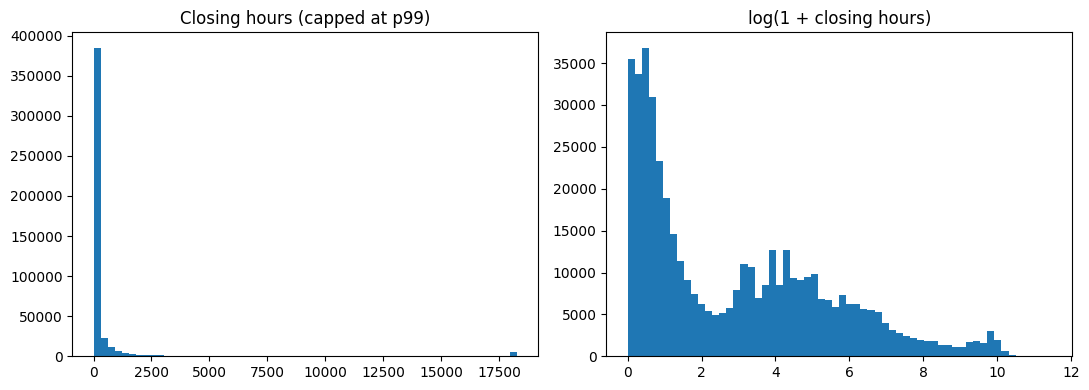

In [13]:
closed = closed_cases(cases)
print(duration_summary(closed["closing_hours"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
upper_cap = closed["closing_hours"].quantile(0.99)
axes[0].hist(closed["closing_hours"].clip(upper=upper_cap), bins=60)
axes[0].set_title("Closing hours (capped at p99)")
axes[1].hist(np.log1p(closed["closing_hours"]), bins=60)
axes[1].set_title("log(1 + closing hours)")
plt.tight_layout()
plt.show()

<div dir="rtl">

**نتیجه نمودار ۱:**

با توجه به توزیعِ چوله‌دار و تحلیلِ لگاریتمی، مشخص شد که سیستمِ پاسخ‌دهی دو‌مُدی است؛ یعنی ترکیبی از شکایات فوری (سریع) و شکایات فرآیندی (کند) داریم. همچنین به دلیل وجود داده‌های پرتِ بسیار بزرگ (بیشینه حدود ۹۴ هزار ساعت)، شاخصِ میانه معیار بسیار معتبرتری نسبت به میانگین برای سنجش عملکرد سیستم است.

</div>

<div dir="rtl">

### آمار توصیفی برای نوع شکایت‌های پرتعداد
توزیع کل، ترکیبی از نوع شکایت‌های متفاوت است. پس همین آمار را برای چند نوع شکایت پرتعداد جدا حساب می‌کنیم. ستون `mean_to_median` نسبت میانگین به میانه است و هرچه از ۱ بزرگ‌تر باشد، دنباله راست توزیع سنگین‌تر است. این نسبت دلیل ما برای گزارش **میانه** در همه جدول‌هاست.

</div>

,cases,mean_hours,median_hours,p90_hours,max_hours,mean_to_median
complaint_type,,,,,,
Illegal Parking,63803,2.06,1.02,4.26,3893.00,2.02
Noise - Residential,52537,16.62,0.91,6.39,952.35,18.22
HEAT/HOT WATER,37991,56.69,44.80,109.69,17521.22,1.27
Blocked Driveway,23428,2.56,1.18,4.62,3297.83,2.16
Noise - Street/Sidewalk,21296,1.80,0.71,3.22,1187.02,2.53
UNSANITARY CONDITION,14673,702.36,310.77,1634.70,17821.97,2.26
Street Condition,11220,86.48,29.43,185.64,33981.88,2.94
Abandoned Vehicle,9425,2.48,1.19,5.27,2187.04,2.08


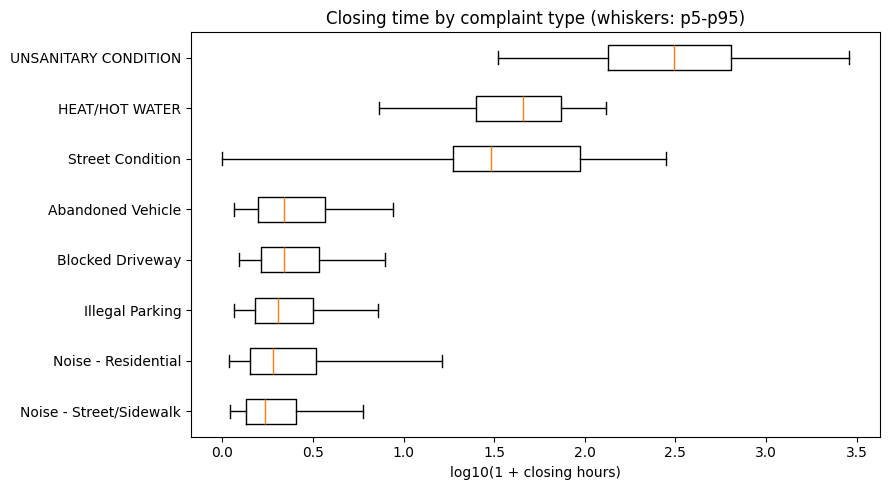

In [14]:
type_summary = duration_by_type(closed, top_n=8)
display(type_summary)

ordered_types = type_summary.sort_values("median_hours").index
duration_groups = [np.log10(1 + closed.loc[closed["complaint_type"] == name, "closing_hours"])
                   for name in ordered_types]

fig, axis = plt.subplots(figsize=(9, 5))
axis.boxplot(duration_groups, vert=False, whis=(5, 95), showfliers=False)
axis.set_yticklabels(ordered_types)
axis.set_xlabel("log10(1 + closing hours)")
axis.set_title("Closing time by complaint type (whiskers: p5-p95)")
plt.tight_layout()
plt.show()

<div dir="rtl">

**نتیجه نمودار ۲:**

نوع شکایت بزرگ‌ترین عامل تفاوت در مدت رسیدگی است: جعبه‌های نوع‌های مختلف روی هم نمی‌افتند و نسبت `mean_to_median` در جدول بالا نشان می‌دهد میانگین 
زیر تأثیر دنباله راست است. نتیجه برای تحلیل این است که مقایسه مناطق باید داخل هر نوع شکایت انجام شود، نه روی مجموع همه نوع‌ها.

شکایت‌های UNSANITARY CONDITION و HEAT/HOT WATER معمولاً زمان رسیدگی طولانی‌تری دارند؛ میانهٔ آن‌ها از بیشتر شکایت‌های دیگر بالاتر است.

در مقابل، Abandoned Vehicle، Blocked Driveway و شکایت‌های مرتبط با سروصدا عموماً سریع‌تر بسته می‌شوند.

پراکندگی زمان رسیدگی در بعضی شکایت‌ها زیاد است؛ یعنی حتی در یک نوع شکایت، مدت بستن پرونده‌ها می‌تواند بسیار متفاوت باشد.

</div>

<div dir="rtl">

## ۱۰. شناسایی و تعیین تکلیف `outlier`
روش `IQR` روی مقیاس لگاریتمی، چون توزیع چوله است. در سلول زیر سهم پرت‌ها، حد بالای مجاز بر حسب ساعت و پنج بزرگ‌ترین مدت‌ها چاپ می‌شود تا تصمیم با عدد پشتیبانی شود.

</div>

In [15]:
is_outlier = flag_outliers_log(closed["closing_hours"])
closed["is_outlier"] = is_outlier

lower_log, upper_log = iqr_bounds(np.log1p(closed["closing_hours"]))
print("outlier count:", int(is_outlier.sum()), "| share:", round(float(is_outlier.mean()), 4))
print("upper bound (hours):", round(float(np.expm1(upper_log)), 1))
print(closed.groupby("is_outlier")["closing_hours"].describe())
closed.nlargest(5, "closing_hours")[["unique_key", "created_date", "closed_date", "closing_hours"]]

outlier count: 1 | share: 0.0
upper bound (hours): 47938.5
               count      mean      std       min       25%       50%       75%       max
is_outlier                                                                               
False       456642.0    637.91  2825.41      0.00      0.86      7.30    107.00  41159.08
True             1.0  94305.49      NaN  94305.49  94305.49  94305.49  94305.49  94305.49


,unique_key,created_date,closed_date,closing_hours
122250,54304503,2022-05-28 14:30:51,2033-03-01 00:00:00,94305.49
33326,53300093,2022-02-07 15:12:24,2026-10-19 14:17:07,41159.08
53605,53535433,2022-03-03 14:27:00,2026-09-24 18:11:00,39987.73
1631,52955143,2022-01-03 15:03:00,2026-07-15 11:20:00,39692.28
82563,53871163,2022-04-09 15:10:11,2026-10-13 11:30:00,39548.33


In [16]:
closed = closed.loc[~is_outlier].reset_index(drop=True)

<div dir="rtl">

تصمیم: رکوردهای پرت شناسایی و فقط از نسخه کاری `closed` در `EDA` حذف شدند، چون حضورشان میانگین‌ها و روند زمانی را به‌شدت منحرف می‌کند. در `cases.csv` همه رکوردها می‌مانند و حذف روی داده خروجی کارخانه اعمال نشده است. تعداد و سهم دقیق پرت‌ها و حد بالای مجاز در خروجی سلول بالا آمده است.

</div>

<div dir="rtl">

## ۱۲. رابطه متغیرهای دسته‌ای: نوع شکایت و منطقه
میانه مدت بسته‌شدن را برای هر ترکیب `borough` و ده نوع شکایت پرتعداد در یک نقشه حرارتی می‌بینیم. رنگ بر پایه لگاریتم میانه است تا نوع‌های سریع و کند هر دو دیده شوند و عدد داخل هر خانه میانه واقعی (ساعت) است. زیر نمودار هم سریع‌ترین نوع هر `borough` و تعداد نوع‌هایی که هر `borough` در آن‌ها کندترین است چاپ می‌شود.

</div>

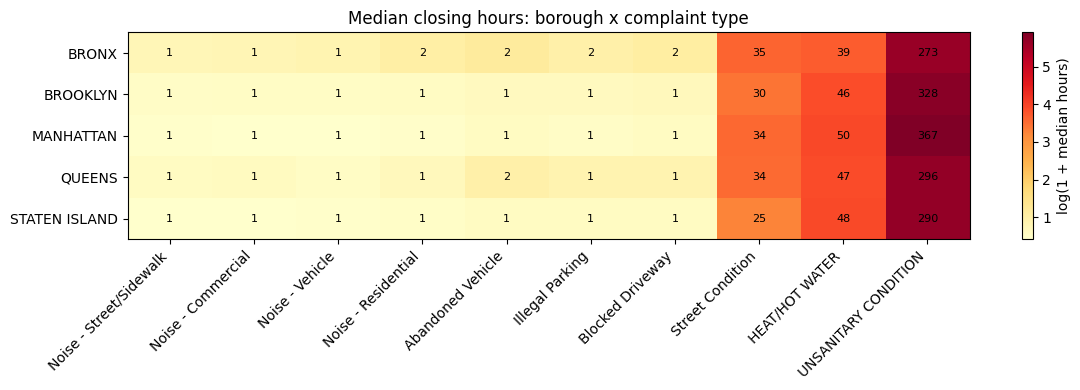

borough
BRONX            Noise - Street/Sidewalk
BROOKLYN         Noise - Street/Sidewalk
MANHATTAN             Noise - Commercial
QUEENS                   Noise - Vehicle
STATEN ISLAND         Noise - Commercial
dtype: object
BRONX        8
MANHATTAN    2
Name: count, dtype: int64


In [18]:
borough_type = median_by_borough_and_type(closed, top_n=10)

fig, axis = plt.subplots(figsize=(12, 4))
image = axis.imshow(np.log1p(borough_type.values), cmap="YlOrRd", aspect="auto")
axis.set_xticks(range(borough_type.shape[1]), borough_type.columns, rotation=45, ha="right")
axis.set_yticks(range(borough_type.shape[0]), borough_type.index)
for row in range(borough_type.shape[0]):
    for col in range(borough_type.shape[1]):
        axis.text(col, row, f"{borough_type.iloc[row, col]:.0f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, label="log(1 + median hours)")
axis.set_title("Median closing hours: borough x complaint type")
plt.tight_layout()
plt.show()

print(fastest_type_per_borough(borough_type))
print(slowest_borough_counts(borough_type))

<div dir="rtl">

**نتیجه نمودار :**

۱. شکایت‌های زیرساختی مثل UNSANITARY CONDITION و HEAT/HOT WATER در تمام مناطق (Boroughs) به طور چشمگیری زمان‌برتر از سایر موارد هستند

۲. شکایت‌های محلی و شهری مثل انواع سر و صدا، پارک غیرمجاز و خودروهای رهاشده، در همه مناطق بسیار سریع‌تر (تقریباً زیر ۲ ساعت) بسته می‌شوند.

۳. الگوی شهری یکنواخت: تفاوت زمان رسیدگی میان مناطق مختلف برای یک نوع شکایت مشخص نسبتاً ناچیز است؛ یعنی نوع شکایت بسیار بیشتر از منطقه تعیین‌کنندهٔ زمان بستن پرونده است.



</div>

<div dir="rtl">

## ۱۳. مقایسه نوع شکایت، آژانس‌ها و بخش‌های شهر

</div>

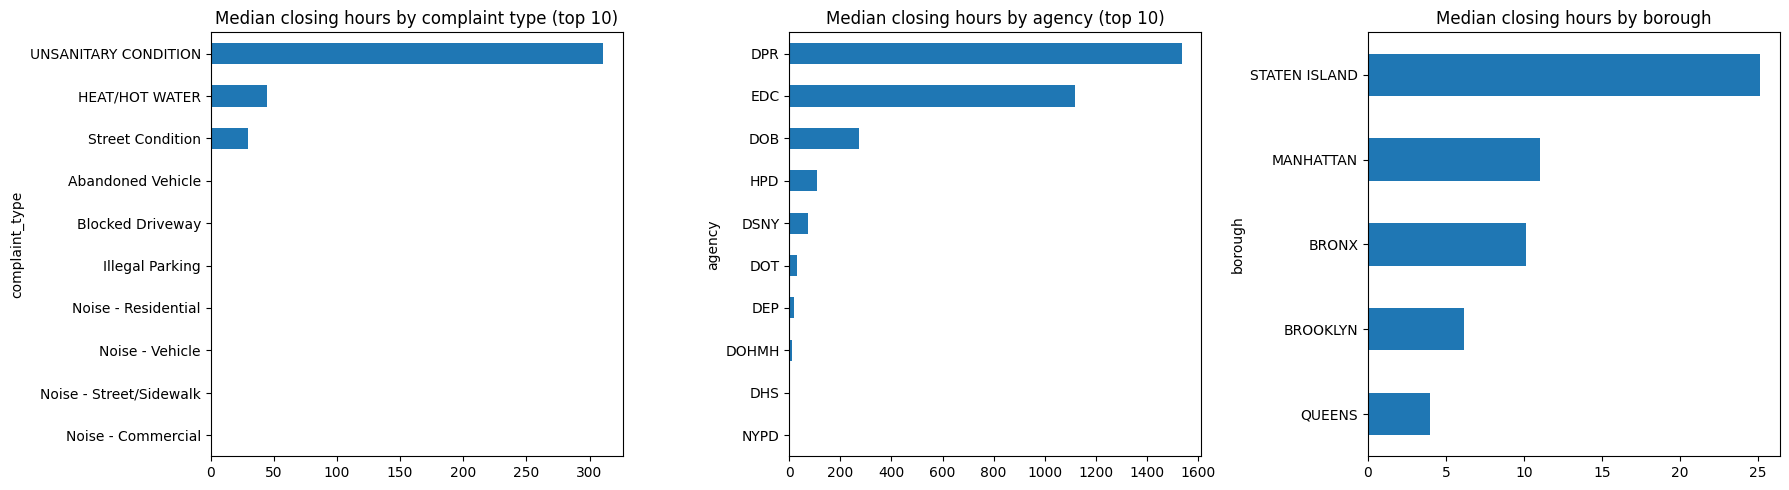

In [19]:
complaint_median = median_by_group(closed, "complaint_type", top_n=10)
agency_median = median_by_group(closed, "agency", top_n=10)
borough_median = closed.groupby("borough")["closing_hours"].median().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

complaint_median.plot.barh(ax=axes[0], title="Median closing hours by complaint type (top 10)")
agency_median.plot.barh(ax=axes[1], title="Median closing hours by agency (top 10)")
borough_median.plot.barh(ax=axes[2], title="Median closing hours by borough")

plt.tight_layout()
plt.show()

<div dir="rtl">

۱. تفاوت فاحش بر اساس نوع شکایت: شکایت‌های مسکونی/ساختمانی مثل UNSANITARY CONDITION با میانه بیش از ۳۰۰ ساعت بسیار زمان‌برتر هستند، در حالی که شکایت‌های عمومی و خیابانی (مثل پارک و سروصدا) عموماً زیر چند ساعت بسته می‌شوند.

۲. تفاوت محسوس میان سازمان‌ها (Agencies): سازمان‌هایی مانند DPR (پارک‌ها) و EDC رسیدگی‌های بسیار طولانی‌تر (بیش از ۱۰۰۰ ساعت) دارند، در حالی که سازمان‌های واکنش سریع مثل NYPD و DHS پرونده‌ها را در کمترین زمان ممکن می‌بندند.

۳. نابرابری جغرافیایی در سرعت پاسخگویی: زمان بستن پرونده‌ها در مناطق یکسان نیست؛ STATEN ISLAND با میانه ۲۵ ساعت کندترین عملکرد و QUEENS (با حدود ۴ ساعت) سریع‌ترین سرعت رسیدگی به پرونده‌ها را دارد.

</div>

<div dir="rtl">

## ۱۴. روند ماهانه
پرونده‌های ماه‌های آخر بازه ممکن است هنوز باز باشند. نمودار سمت راست سهم پرونده‌های باز در هر ماه را نشان می‌دهد تا این اثر در تفسیر روند دیده شود.

</div>

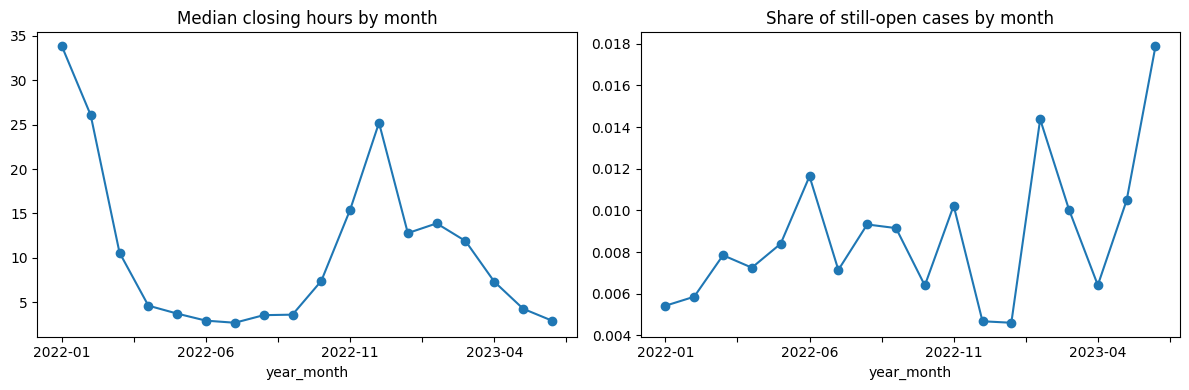

In [20]:
trend = monthly_median(closed)
open_share_by_month = 1 - cases.groupby("year_month")["is_closed"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
trend.plot(ax=axes[0], marker="o", title="Median closing hours by month")
open_share_by_month.plot(ax=axes[1], marker="o", title="Share of still-open cases by month")
plt.tight_layout()
plt.show()

<div dir="rtl">

الگوی فصلی شدید در زمان بستن پرونده‌ها: نمودار سمت چپ (Median closing hours by month) نشان می‌دهد که زمان رسیدگی به پرونده‌ها در ماه‌های سرد سال (پاییز و زمستان، به‌ویژه ژانویه) به شدت افزایش می‌یابد (تا ۳۴ ساعت)، در حالی که در تابستان به کف خود (زیر ۳ ساعت) می‌رسد که نشان‌دهندهٔ تأثیر مستقیم فصل بر نوع و حجم شکایات (مانند مشکلات سیستم گرمایشی) است.
</div>

<div dir="rtl">

## ۱۵. بهتر یا بدتر شدن مدت زمان حل پرونده
چون روند ماهانه فصلی است، مقایسه ماه‌به‌ماه گمراه‌کننده است. پس سال اول بازه را با سال آخر، فقط در ماه‌هایی که در هر دو سال هست، مقایسه می‌کنیم (`YoY`). تغییر منفی یعنی پرونده‌ها سریع‌تر بسته شده‌اند، یعنی بهبود. نمودار چپ میانه دو سال را کنار هم می‌گذارد و نمودار راست درصد تغییر را با رنگ نشان می‌دهد. جدول پایین همین مقایسه را برای ده نوع شکایت پرتعداد در سطح شهر می‌دهد.

</div>

comparing 2022 vs 2023, months: [1, 2, 3, 4, 5, 6]


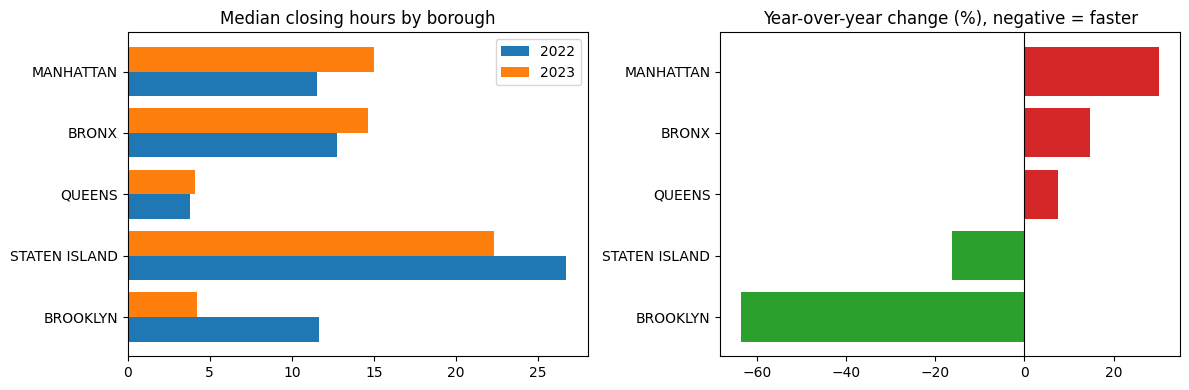

year,borough,median_previous,median_current,change_pct
1,BROOKLYN,11.65,4.24,-63.61
4,STATEN ISLAND,26.68,22.34,-16.29
3,QUEENS,3.82,4.11,7.59
0,BRONX,12.78,14.67,14.77
2,MANHATTAN,11.51,14.98,30.23


year,complaint_type,median_previous,median_current,change_pct
8,Street Condition,42.45,24.34,-42.67
6,Noise - Street/Sidewalk,0.78,0.60,-23.04
2,HEAT/HOT WATER,45.97,35.93,-21.85
5,Noise - Residential,0.96,0.78,-18.68
9,UNSANITARY CONDITION,320.61,268.78,-16.17
4,Noise - Commercial,0.72,0.61,-15.46
7,Noise - Vehicle,0.72,0.69,-4.02
3,Illegal Parking,0.92,1.09,18.13
1,Blocked Driveway,1.02,1.33,30.54
0,Abandoned Vehicle,1.00,1.32,31.56


In [21]:
previous_year, current_year, shared_months = compared_period(closed)
print(f"comparing {previous_year} vs {current_year}, months: {shared_months}")

yoy_borough = year_over_year(closed, by=("borough",)).sort_values("change_pct")
positions = np.arange(len(yoy_borough))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(positions - 0.2, yoy_borough["median_previous"], height=0.4, label=str(previous_year))
axes[0].barh(positions + 0.2, yoy_borough["median_current"], height=0.4, label=str(current_year))
axes[0].set_yticks(positions, yoy_borough["borough"])
axes[0].set_title("Median closing hours by borough")
axes[0].legend()

bar_colors = np.where(yoy_borough["change_pct"] < 0, "tab:green", "tab:red")
axes[1].barh(yoy_borough["borough"], yoy_borough["change_pct"], color=bar_colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Year-over-year change (%), negative = faster")
plt.tight_layout()
plt.show()

top_types = closed["complaint_type"].value_counts().head(10).index
yoy_type = year_over_year(closed[closed["complaint_type"].isin(top_types)], by=("complaint_type",))
display(yoy_borough.round(2))
display(yoy_type.sort_values("change_pct").round(2))

<div dir="rtl">


۱. تضاد عملکردی در مناطق (Boroughs)
پیشرفت چشمگیر در بروکلین: بروکلین با کاهش ۶۳ درصدی زمان بستن پرونده‌ها، عملکردی فوق‌العاده داشته است. این منطقه احتمالاً تغییرات مدیریتی یا عملیاتی موفقی داشته که باعث سرعت عمل بسیار بالا شده است.
افت عملکرد در منهتن و برانکس: در مقابل، منهتن (+۳۰٪) و برانکس (+۱۴٪) با کندتر شدن فرآیندها مواجه بوده‌اند. این شکاف نشان می‌دهد که “سیاست یکسان” در همه مناطق جواب نداده و احتمالا منهتن با افزایش حجم پرونده یا کمبود منابع برای رسیدگی سریع روبروست.

۲. تغییر اولویت‌ها در انواع شکایت
این بخش از داده‌ها بسیار جالب است و یک “جابجایی اولویت” را نشان می‌دهد:

بهبود در مشکلات زیرساختی و جدی: شکایات سخت و زیرساختی مانند Street Condition (۴۲٪ سریع‌تر)، HEAT/HOT WATER (۲۲٪ سریع‌تر) و UNSANITARY CONDITION (۱۶٪ سریع‌تر) همگی بهبود یافته‌اند. این یعنی مدیریت شهری احتمالاً منابع خود را روی مشکلات کلان و ضروری متمرکز کرده است.
کندی در شکایات اجرایی (Enforcement): در عوض، شکایات ساده‌تر و اجرایی مثل Abandoned Vehicle (+۳۱٪)، Blocked Driveway (+۳۰٪) و Illegal Parking (+۱۸٪) همگی کندتر شده‌اند.
نتیجه‌گیری نهایی:

تحلیل نشان می‌دهد که سیستم در سال ۲۰۲۳ به نفع “کیفیت زندگی و زیرساخت‌ها” تغییر جهت داده است؛ یعنی رسیدگی به گرمایش و بهداشت عمومی (که حیاتی‌تر هستند) را در اولویت قرار داده و رسیدگی به امور انضباطی و ترافیکی (که معمولاً ساده‌تر هستند اما زمان‌گیر) در اولویت دوم قرار گرفته و کندتر شده‌اند.

 نتایج نشان می‌دهد که پاسخ به سؤال «بهبود یا افت؟» در سطح شهر یکنواخت نیست و کاملاً به منطقه (`borough`) بستگی دارد.

</div>

<div dir="rtl">

## ۱۶. مقابله کد پستی با ستون `borough`
کد پستی‌هایی که در داده زیر بیش از یک `borough` آمده‌اند، یافته کیفیت داده هستند. علاوه بر شمردن این کدها، اندازه اثر اصلاح پیشنهادی را هم می‌سنجیم: اگر همه سطرهای هر کد پستی به پرتکرارترین `borough` همان کد تبدیل شوند، چند سطر تغییر می‌کند.

</div>

In [22]:
conflicts = zip_borough_conflicts(cases)
print("zip codes with more than one borough:", conflicts["incident_zip"].nunique())
print("effect of assigning each zip to its most frequent borough:", modal_borough_effect(cases))
conflicts.head(20)

zip codes with more than one borough: 4
effect of assigning each zip to its most frequent borough: {'rows_changed': 230, 'share_changed_pct': 0.0499, 'zip_codes_affected': 4}


,incident_zip,borough,n
29,10030,MANHATTAN,2560
30,10030,QUEENS,1
111,10463,BRONX,4021
112,10463,MANHATTAN,225
142,11208,BROOKLYN,5283
143,11208,QUEENS,2
204,11385,QUEENS,6340
203,11385,BROOKLYN,2


<div dir="rtl">

برای حل این مشکل می‌توانیم برای هر کد پستی، تمام ردیف‌ها را به پرتکرارترین `borough` همان کد پستی تغییر بدهیم. این اصلاح روی `cases.csv` اعمال نشده است و فقط در جدول عریض سطح `borough` (بخش ۸) استفاده می‌شود.

</div>

<div dir="rtl">

## ۱۷. یافته‌های غیربدیهی
۱. معاوضهٔ اولویت‌ها: تسریع در کارهای سخت و زیرساختی به قیمت افت کارهای ساده
انتظار اولیه (شهودی): وقتی گفته می‌شود وضعیت شهرداری در سال جدید در مجموع تغییر کرده، انتظار داریم رسیدگی به همهٔ کارها یک‌دست کندتر یا سریع‌تر شده باشد، یا لااقل کارهای ساده همیشه سریع‌تر بمانند.
یافتهٔ داده: شهرداری دقیقاً رفتاری شبیه «اولویت‌بندی منابع محدود» نشان داده است؛ شکایات سنگین و حیاتی مانند آسفالت و خیابان‌ها (Street Condition تا ۴۲٪-)، گرمایش زمستانی (HEAT/HOT WATER تا ۲۲٪-) و بهداشت مسکن (UNSANITARY تا ۱۶٪-) نسبت به سال قبل به شکل چشمگیری سریع‌تر حل شده‌اند. اما در نقطهٔ مقابل، شکایات ساده، تکراری و ترافیکی مثل خودروهای سد معبر و پارک غیرمجاز (Blocked Driveway و Abandoned Vehicle) بین ۱۸٪ تا ۳۱٪ کندتر شده‌اند.

۲. واگرایی شدید جغرافیایی (عدم وجود یک روند واحد برای کل نیویورک)
انتظار اولیه (شهودی): پاسخ به سؤال «آیا عملکرد شهرداری بهتر شده یا بدتر؟» باید یک روند مشخص در سطح شهر باشد.
یافتهٔ داده: پاسخ در مناطق مختلف کاملاً متناقض است! در حالی که بروکلین با جهش عملیاتی فوق‌العاده زمان بستن پرونده را ۶۳.۶٪ کاهش داده (از ۱۱.۶ به ۴.۲ ساعت)، منهتن با افزایش زمان رسیدگی، ۳۰.۲٪ کندتر شده است (از ۱۱.۵ به ۱۵ ساعت). این نشان می‌دهد سنجش عملکرد در سطح کل شهر (City-wide aggregation) تصویر غلط و گمراه‌کننده‌ای می‌سازد و گلوگاه‌ها کاملاً منطقه‌ای هستند.

۳. اثر فصل بسیار تعیین‌کننده‌تر از بازدهی سیستم است (دام مقایسهٔ ماه‌های متوالی)
انتظار اولیه (شهودی): برای ارزیابی راندمان شهرداری، کافی است ببینیم عملکرد ماه به ماه (مثلاً ژانویه نسبت به ژوئن) چگونه تغییر می‌کند.
یافتهٔ داده: میانه زمان بستن پرونده‌ها در زمستان (ژانویه) به ۳۴ ساعت می‌رسد، در حالی که در تابستان (ژوئن) تا مرز زیر ۳ ساعت سقوط می‌کند (بیش از ۱۰ برابر تفاوت!). این جهش ناشی از تنبلی یا زرنگی سازمان‌ها نیست، بلکه ناشی از نوع شکایت‌های تحمیل‌شده با فصل (هجوم شکایات سیستم‌های گرمایشی و ترکیدگی لوله‌ها) است. بنابراین هرگونه مقایسهٔ ماه به ماه گمراه‌کننده است و ارزیابی فقط باید به صورت سال‌به‌سال (YoY در همان ماه مشخص) انجام شود.

</div>